In [1]:
# The purpose of this notebook is to implement a simple
# neural network from scratch using JAX.

In [1]:
import numpy as np
import pylab as plt
import jax
import jax.numpy as jnp

Text(0.5, 1.0, 'Toy regression dataset')

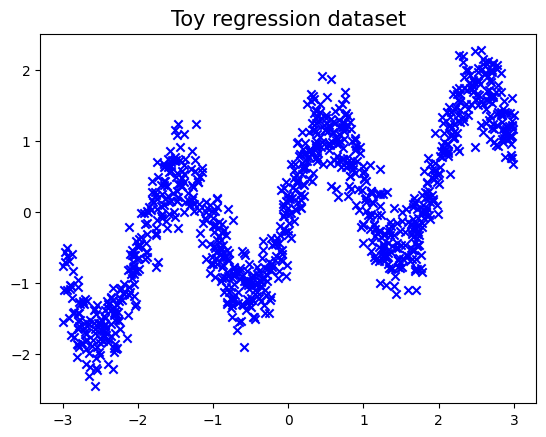

In [2]:
################################################
# First, let us create a toy regression dataset
################################################

def unkonwn_function(x):
    return 0.3*x + np.sin(np.pi*x)

# let us create a dataset
N = 10**3
data_x = -3 + 6*np.random.rand(N)
data_y = unkonwn_function(data_x) + 0.3*np.random.randn(N)

# plot the dataset
plt.scatter(data_x, data_y, marker='x', color="blue")
plt.title("Toy regression dataset", fontsize=15)

In [68]:
# let us implement a JAX function that implements
# a simple MLP neural network with L layers. The function 
# should take as input the weights of the network represented 
# as a list of (Matrix, Vector):
#    weight = [(A1, b1), (A2, b2), ..., (An, bn)]
# as well as the input data x and return the output of the network.
#
# The output of the network is given by:
# x_1 = relu(A1*x_{input} + b1)
# x_2 = relu(A2*x_1 + b2)
# ...
# x_{n-1} = relu(A_{n-1}*x_{n-2} + b_{n-1})
# y = A_n*x_{n-1} + b_n 
# 
# remark: note that there is no non-linearity 
# after the last layer.

def relu(x):
    return jnp.maximum(0, x)

#@jax.jit
def net(params, # the list of paramaters
        x,      # a single input
        ):
    num_layers = len(params)
    #print("Number of layers:", num_layers)
    for i in range(num_layers-1):
        A, b = params[i]
        x = relu(jnp.dot(A, x) + b)
    #last layer no non-linearity
    A,b = params[-1]
    y= jnp.dot(A, x) + b
    return y

In [9]:
# let us define a function that generates the initial weights
# given the number of layers and the number of neurons per layer
# The function takes as input the dimension of each layer, 
# including the input and output layers.

def init_weights(layer_dims):
    params=[]
    # your code here
    number_of_layers = len(layer_dims)
    for layer_index in range(1, number_of_layers):
        d_input=layer_dims[layer_index-1]
        d_output=layer_dims[layer_index]
        # we divide by np.sqrt(d_input) to avoid overflows
        A = np.random.normal(0,1, size=(d_output, d_input)/np.sqrt(d_input))
        b = np.random.normal(9,1, size=(d_output, 1))
        params.append((A, b))
    return params

# let us create a function that counts the number of parameters
# in the network
def count_params(params):
    param_count=0
    # your code here
    for param in params:
        A, b = param
        param_count += A.size + b.size
    return param_count

#params=init_weights([2, 3, 1,5,5])
#count_params(params)

In [10]:
# let us test the implementation by creating a simple network
# with 2 layers and 10 neurons per layer
params = init_weights([1, 30, 30, 1])

# let us count the number of parameters
print("Number of parameters in the network:", count_params(params))

# sanity check: let us evaluate the network on a single input
net(params, jnp.array([1.0]))

TypeError: 'numpy.float64' object cannot be interpreted as an integer

In [79]:
# let us `vmap` the network function so that it can take as input
# a batch of inputs and return a batch of outputs
net_batch = jax.vmap(net, in_axes=(None, 0))

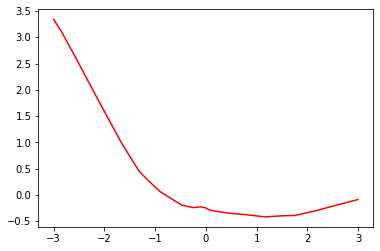

In [80]:
# let us plot the regression function
x_input = jnp.linspace(-3, 3, 1000)

# we need to add a "fake" last dimension to the input
# to make it compatible with the network
x_input = x_input[..., jnp.newaxis]
y_output = net_batch(params, x_input)

# get rid of the last dimension for y_output
# to make it compatible with the plot function
y_output = y_output[..., 0]

plt.plot(x_input, y_output, color="red")

In [81]:
# let us define the loss function
# we will use the mean squared error
# the functions takes as input the parameters of the network
# as well as a batch of inputs and a batch of outputs
# and returns the mean squared error defined as
#     MSE = 1/N * sum_i (y_i - y_pred_i)^2

@jax.jit
def loss(params,  # parameters of the network
         x,       # batch of inputs
         y,       # batch of outputs
         ):
    y_pred = net_batch(params, x)
    return jnp.mean((y - y_pred)**2)

# value and gradient of the loss function
# we use `jax.value_and_grad` to compute the value and the gradient
# of the loss function with respect to the first argument
# (the parameters of the network)
loss_value_and_grad = jax.jit(jax.value_and_grad(loss))


In [82]:
# let us train the network using gradient descent

# learning rate
lr = 0.01
# number of epochs
n_epochs = 10000
# batch size
batch_size = 256
# number of batches per epoch
n_batches = N // batch_size
# let us keep track of the loss
losses = []

# let us train the network
params = init_weights([1, 10, 10, 1])
for epoch in range(n_epochs):
    # shuffle the data
    
    #
    # your code here
    #

    # stores all the losses for this epoch
    epoch_losses = []
    for batch in range(n_batches):
        # generate a random bath of indicies
        idx = np.random.choice(N, batch_size, replace=False)
        x_batch = data_x[idx]
        y_batch = data_y[idx]
        # compute the loss value and the gradient
        loss_value, grad = loss_value_and_grad(params, x_batch[...,jnp.newaxis], y_batch)
        # do param update
        for i in range(len(params)):
            params[i] = params[i] - lr*grad[i]
        #

    # display the loss every 100 epochs
    if epoch % 500 == 0:
        print(f"Epoch {epoch+1}/{n_epochs}, loss = {np.mean(epoch_losses)}")
    

Epoch 1/10000, loss = 2.4057037830352783
Epoch 501/10000, loss = 0.3508850634098053
Epoch 1001/10000, loss = 0.21722285449504852
Epoch 1501/10000, loss = 0.16862685978412628
Epoch 2001/10000, loss = 0.1460929960012436
Epoch 2501/10000, loss = 0.13743449747562408
Epoch 3001/10000, loss = 0.130385160446167
Epoch 3501/10000, loss = 0.13899503648281097
Epoch 4001/10000, loss = 0.1286161094903946
Epoch 4501/10000, loss = 0.1128881573677063
Epoch 5001/10000, loss = 0.14251825213432312
Epoch 5501/10000, loss = 0.10400345921516418
Epoch 6001/10000, loss = 0.10265494138002396
Epoch 6501/10000, loss = 0.14619344472885132
Epoch 7001/10000, loss = 0.11649459600448608
Epoch 7501/10000, loss = 0.10353589057922363
Epoch 8001/10000, loss = 0.09541555494070053
Epoch 8501/10000, loss = 0.10114205628633499
Epoch 9001/10000, loss = 0.09761771559715271
Epoch 9501/10000, loss = 0.09234268218278885


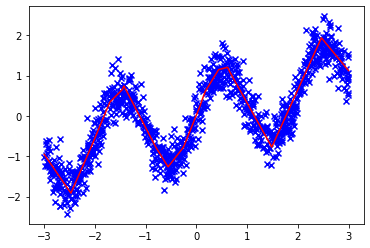

In [84]:
# let us plot the regression function
x_input = jnp.linspace(-3, 3, 1000)

# we need to add a "fake" last dimension to the input
# to make it compatible with the network
x_input = x_input[..., jnp.newaxis]
y_output = net_batch(params, x_input)

# get rid of the last dimension for y_output
# to make it compatible with the plot function
y_output = y_output[..., 0]

plt.figure()
plt.scatter(data_x, data_y, marker='x', color="blue")
plt.plot(x_input, y_output, color="red")